# Devoir maison 2 — carnets J3 et J4

> **À rendre avant la séance 5** — comme tout devoir, avant la première séance de la semaine
> suivante. Ce devoir porte sur **J3** (comparer sans se mentir, puis ce qu’on fait des défauts
> trouvés) et sur **J4** (la mesure, et la révélation). Il se fait **seul**, à la maison, et il se
> rend.

**Ce qu’on rend :** ce carnet, rempli, déposé dans votre **dépôt GitHub personnel** avec la
déclaration d’usage de l’IA (`declaration_DM2.md`). **Le journal de nettoyage** et **le tableau à
quatre colonnes** en sont les pièces principales.

**Pourquoi ce devoir :** chaque question demande une mesure que **vous** produisez — pas une
lecture. Si vous n’avez pas compris, ça se verra tout de suite ; c’est fait pour ça.

**Ce qui est lu.** Ce qui est lu ici : **les tableaux** et le code. Les tableaux : le tableau à quatre colonnes, le
journal de nettoyage, vos métriques. Le code : là où il produit un chiffre. **Ce dépôt est
relevé** : il est lu. Les **sept devoirs** comptent ensemble pour **10 % de la
note**. C'est la composante « exercices et devoirs » du cours (25 %, avec E1, E2, E3).
**Il n’y a pas d’oral sur les devoirs** : l’oral individuel, en fin de parcours, porte sur
l’ensemble de votre travail.

**Trois mots, pour être sûr :**

- **la baseline** — le modèle bête qu’il faut battre : la réponse constante, ou la règle du délai en
  place. Un score ne se lit jamais seul.
- **la barre de bruit** — de combien un score bouge tout seul ; en dessous, un écart n’est pas un
  gain.
- **le coût et le seuil** — ce que le métier paie pour chaque erreur, et le niveau de probabilité
  au-delà duquel on alerte.

---

## Comment ça marche

1. La partie **« Mise en place »** est **fournie** : exécutez-la, ne la modifiez pas. C’est elle
   qui lit les données, construit la table, mesure les baselines, la matrice et le coût — sans
   elle, aucune question ne peut tourner.
2. Chaque **question** porte sa consigne, un squelette et des **contrôles de forme**. Ils
   vérifient la forme de votre réponse : un pourcentage, une dimension, une cohérence avec
   vos autres réponses). Ils ne donnent **jamais** la réponse, et ils se taisent tant que vous
   n’avez pas écrit.
3. Une réponse se **chiffre** ou s’**écrit** — jamais « ça a marché ». **Deux** questions demandent
   d’**annoncer ce que vous attendez avant de mesurer** : c’est volontaire.
4. **Votre échantillon personnel** : dans la mise en place, remplacez `MON_IDENTIFIANT` par votre
   pseudo GitHub. Deux questions (Q9, Q10) se calculent **sur votre échantillon** : sans cela, vos
   chiffres sont ceux de tout le monde, et votre copie se recopie d’un voisin.
5. **Cœur** et **approfondissement** se rendent dans le **même dépôt**. La
   différence ne porte pas sur la note : elle dit où porter votre effort.
6. À la fin : les **trois tableaux**, puis le **dépôt**.

> **Ce qui est évalué, et ce qui se lit.** Trois objets traversent tout le cours, et on vous
> interrogera dessus — en devoir, au partiel, à l’oral. Le premier est la fonction `predict` :
> l’interface que le professeur appelle sur une table brute. Le deuxième est le **tableau d’essais** :
> ce que vous avez annoncé, essayé, mesuré. Le troisième est le **journal de nettoyage** : chaque
> décision, son choix, son effet mesuré. Ce qu’ils **retournent** est ce qu’on vous demandera de
> défendre — et votre projet s’appuiera dessus.


## Mise en place (fournie)

Exécutez cette partie **de haut en bas**, sans rien y modifier. Elle reprend la chaîne des
carnets : les données, la table, les baselines et la barre, la matrice de confusion, le
coût métier.

Les `random_state=0` sont la **graine du tirage au sort** (expliquée en
J1 §5). Le même nombre redonne le même découpage, donc la même mesure.


### Les outils


### Explication — importer l'outil d'affichage

Cette cellule importe `display`, qui permet de présenter les tableaux proprement dans Kaggle. Elle ne calcule encore aucun résultat.

In [1]:
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


### Les données


### Explication — retrouver les fichiers de données

Cette cellule cherche automatiquement le dossier contenant `train.csv` dans Kaggle. Elle évite de dépendre d'un chemin fixe qui pourrait changer.

In [2]:
import os
import pandas as pd
import numpy as np
# où sont les fichiers — on CHERCHE `train.csv`, on ne suppose pas un chemin
# (Kaggle a déjà déplacé ses points de montage : un chemin recopié se périme, une recherche non)
def _trouver_dossier(racines):
    """Première racine contenant train.csv — en surface, puis en profondeur."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        if os.path.exists(os.path.join(racine, "train.csv")):
            return racine
        for chemin, _, fichiers in os.walk(racine):
            if "train.csv" in fichiers:
                return chemin
    return None

DOSSIER = _trouver_dossier(["/kaggle/input", "sortie"])
assert DOSSIER, "train.csv introuvable : les données de la compétition sont-elles montées ?"


### Explication — charger les données

`read_csv` lit les deux fichiers. `train` contient les observations et la cible `patient_absent`; `test` contient les lignes à prédire. L'affichage permet de vérifier les dimensions et les colonnes.

In [3]:
train = pd.read_csv(os.path.join(DOSSIER, "train.csv"), low_memory=False)
test = pd.read_csv(os.path.join(DOSSIER, "test.csv"), low_memory=False)

ID, CIBLE = "ligne_id", "patient_absent"


print("Dimensions de train :", train.shape)
print("Dimensions de test :", test.shape)
print("Colonnes de la cible :", CIBLE)
display(train.head())

Dimensions de train : (149894, 39)
Dimensions de test : (63721, 38)
Colonnes de la cible : patient_absent


,dossier_id,ligne_id,patient_id,clinique,district,age,sexe,quartier,assurance,hypertension,...,indice_risque_externe,indice_meteo_jour,zone_clinique,tournee_jour,cout_acte,age_mois,score_territorial,canal_prise,taux_absence_passe,patient_absent
0,DOS-0127912,127913,P070425,C02,D3,53,F,Q04,privée,0,...,86.64,35,urbaine,T00000,10.4,636,-1.1621,guichet,0.0,1
1,DOS-0002883,2884,P109083,C36,D6,38,F,Q01,mutuelle,0,...,40.91,37,urbaine,T00002,5.3,456,-0.0963,guichet,0.0,0
2,DOS-0098561,98562,P036240,C43,D5,35,M,Q52,publique,1,...,28.34,82,urbaine,T00004,13.5,420,0.7951,en ligne,0.0,0
3,DOS-0133156,133157,P033484,C10,D2,36,M,Q07,aucune,0,...,55.91,76,urbaine,T00005,20.4,432,0.3788,guichet,0.0,0
4,DOS-0055744,55745,P035934,C28,D6,32,M,Q02,aucune,0,...,29.68,65,urbaine,T00006,8.8,384,1.2562,téléphone,0.0,0


### La table de travail


### Explication — préparer les variables

On retire les identifiants, les variables à écarter et la cible. Les colonnes de texte sont transformées en catégories. Les catégories du test sont alignées sur celles de l'entraînement pour éviter des colonnes différentes.

In [4]:
A_ECARTER = [ID, "dossier_id", "patient_id", "duree_consultation", "constantes_relevees",
             "motif_absence", "date_prise", "date_rdv", "taille_cm", "date_naissance",
             "canal_prise"]

def matrice(cols):
    """La table de travail : colonnes écartées retirées, catégorielles déclarées."""
    X = cols.drop(columns=[c for c in A_ECARTER + [CIBLE] if c in cols.columns]).copy()
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    trop_fin = [c for c in cat if X[c].nunique() > 255]
    X = X.drop(columns=trop_fin)
    cat = [c for c in cat if c not in trop_fin]
    for c in cat:
        X[c] = X[c].fillna("").astype("category")
    return X, cat, trop_fin

X, CAT, TROP_FIN = matrice(train)
Xt, _, _ = matrice(test)

for c in CAT:
    Xt[c] = Xt[c].cat.set_categories(X[c].cat.categories)


### La cible, et la référence


### Explication — mesurer la répartition de la cible

On compte le nombre de lignes et le nombre d'absences. `reference` représente l'exactitude obtenue en prédisant toujours la classe majoritaire. C'est la première baseline à battre.

In [5]:
repartition = pd.DataFrame({"lignes": [len(train), int(train[CIBLE].sum())],
                            "part (%)": [100.0, round(100 * train[CIBLE].mean(), 2)]},
                           index=["toutes", "absents"])

reference = 100 * max(train[CIBLE].mean(), 1 - train[CIBLE].mean())


print("Répartition de la cible")
display(repartition)
print(f"Baseline constante : {reference:.2f} %")

Répartition de la cible


,lignes,part (%)
toutes,149894,100.00
absents,27357,18.25


Baseline constante : 81.75 %


### Explication — isoler la réponse à prédire

`y` contient uniquement la colonne `patient_absent`. Les variables explicatives sont dans `X`. Il ne faut jamais laisser la cible parmi les variables d'entrée.

In [6]:
# `y` entre ici ; la référence a déjà été calculée avec la distribution ci-dessus —
y = train[CIBLE]


### Le découpage, le modèle, et les baselines


### Explication — séparer apprentissage et validation

On réserve 20 % des lignes pour mesurer les modèles, sans les utiliser pendant l'entraînement. `stratify=y` conserve la proportion d'absences. On calcule ensuite plusieurs baselines et une barre de bruit.

In [7]:
# les baselines, sur le même jeu de validation — et la barre qui décide
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

# 1) la réponse constante : le concurrent le plus bête, et le plus dur à battre
constante = 100 * max(yval.mean(), 1 - yval.mean())

# 2) la règle du délai : « j'annonce une absence si le délai dépasse N jours ».
#    N se choisit sur les lignes d'apprentissage, pas sur celles de contrôle.
delai_max = int(Xtr['delai_jours'].max())
taux_par_seuil = {s: float(((Xtr['delai_jours'] > s).astype(int) == ytr).mean())
                  for s in (0, 1, 3, 7, 14, 30) if s < delai_max}
seuil_appris = max(taux_par_seuil, key=taux_par_seuil.get)
regle = (Xval['delai_jours'] > seuil_appris).astype(int)

# et la règle qui ne dirait jamais rien ? c'est la réponse constante, au point près
silence = (Xval['delai_jours'] > delai_max).astype(int)

# 3) la famille linéaire : elle a besoin de nombres, on lui en prépare — la recette des
#    séances précédentes (newton-cholesky : le solveur qui converge sur cette table)
X_n = pd.get_dummies(X, columns=CAT).fillna(0)   # 0 = trou comblé ; le linéaire ne lit pas les NaN
Xtr_n, Xval_n = X_n.loc[Xtr.index], X_n.loc[Xval.index]
lineaire = LogisticRegression(solver='newton-cholesky').fit(Xtr_n, ytr)

# 4) le modèle du cours, celui des séances précédentes
modele = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# la barre : l'erreur-type de l'exactitude sur CE jeu de validation
barre = 100 * ((constante / 100) * (1 - constante / 100) / len(yval)) ** 0.5

baselines = pd.DataFrame([
    {'baseline': 'toujours présent',
     'exactitude (%)': round(constante, 2)},
    {'baseline': f'règle du délai — absent si le délai dépasse {seuil_appris} j',
     'exactitude (%)': round(100 * (regle == yval).mean(), 2)},
    {'baseline': 'absent si ce patient a déjà manqué un rendez-vous',
     'exactitude (%)': round(100 * ((Xval['taux_absence_passe'] > 0).astype(int) == yval).mean(), 2)},
    {'baseline': 'la famille linéaire',
     'exactitude (%)': round(100 * lineaire.score(Xval_n, yval), 2)},
    {'baseline': 'le modèle du cours',
     'exactitude (%)': round(100 * modele.score(Xval, yval), 2)},
])

ecart = 100 * modele.score(Xval, yval) - constante


print("Baselines sur le jeu de validation")
display(baselines.round(2))
print(f"Barre de bruit : ± {barre:.3f} point")
print(f"Écart du modèle du cours à la baseline : {ecart:+.2f} point")

Baselines sur le jeu de validation


,baseline,exactitude (%)
0,toujours présent,81.75
1,règle du délai — absent si le délai dépasse 30 j,79.92
2,absent si ce patient a déjà manqué un rendez-vous,78.65
3,la famille linéaire,82.21
4,le modèle du cours,82.51


Barre de bruit : ± 0.223 point
Écart du modèle du cours à la baseline : +0.76 point


### La matrice de confusion, et les probabilités


### Explication — construire la matrice de confusion

Le modèle produit une classe 0 ou 1. On compte les vrais positifs, faux positifs, faux négatifs et vrais négatifs. Les probabilités seront réutilisées plus tard pour tester différents seuils.

In [8]:
# les quatre cases, comptées à la main sur le jeu de contrôle
predit = modele.predict(Xval)

VP = int(((predit == 1) & (yval == 1)).sum())   # annoncé absent, et absent
FP = int(((predit == 1) & (yval == 0)).sum())   # annoncé absent, et venu : la fausse alerte
FN = int(((predit == 0) & (yval == 1)).sum())   # annoncé présent, et absent : l’absence manquée
VN = int(((predit == 0) & (yval == 0)).sum())   # annoncé présent, et venu

assert VP + FP + FN + VN == len(yval)

# et la probabilité, qui servira à déplacer le seuil : c’est elle qui décide, pas le 0/1
probabilites = modele.predict_proba(Xval)[:, 1]

# les quatre mêmes cases, retrouvées par la bibliothèque — le contrôle, pas la confiance
from sklearn.metrics import confusion_matrix
confirme = confusion_matrix(yval, predit).ravel()          # ordre : VN, FP, FN, VP
assert (VN, FP, FN, VP) == tuple(int(v) for v in confirme), 'les quatre cases ne concordent pas'


print("Matrice de confusion (VN, FP, FN, VP)")
display(pd.DataFrame([[VN, FP], [FN, VP]], index=["Vérité 0", "Vérité 1"], columns=["Prédit 0", "Prédit 1"]))
print(f"Probabilités calculées : {len(probabilites):,}")

Matrice de confusion (VN, FP, FN, VP)


,Prédit 0,Prédit 1
Vérité 0,24155,353
Vérité 1,4891,580


Probabilités calculées : 29,979


### Le coût métier


### Explication — définir le coût métier

Une fausse alerte coûte 25 unités et une absence manquée coûte 100 unités. La fonction `cout` additionne ces pénalités. Le seuil théorique dépend de ces deux coûts.

In [9]:
# le coût d’une décision, et la dérivation du seuil
COUT_FP, COUT_FN = 25, 100   # les deux montants de l’énoncé, en unités de coût

def cout(decision, verite=yval):
    faux_positifs = int(((decision == 1) & (verite == 0)).sum())
    faux_negatifs = int(((decision == 0) & (verite == 1)).sum())
    return COUT_FP * faux_positifs + COUT_FN * faux_negatifs

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)


print(f"Coût d’une fausse alerte : {COUT_FP}")
print(f"Coût d’une absence manquée : {COUT_FN}")
print(f"Seuil théorique : {seuil_theorique:.3f}")

Coût d’une fausse alerte : 25
Coût d’une absence manquée : 100
Seuil théorique : 0.200


### Les outils du nettoyage


### Explication — mesurer l'effet d'un nettoyage

Ces fonctions réentraînent le modèle sur le même découpage pour comparer les traitements. Cela permet d'isoler l'effet d'une décision de nettoyage.

In [10]:
# un trou aléatoire : cinq traitements, et ce que chacun change
def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)

# le même découpage, les lignes retirées seulement côté apprentissage : le jeu de contrôle
# ne change pas, donc les deux scores se comparent vraiment — ce que `score_de` ne fait pas
def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)


### Explication — documenter les colonnes à écarter

Le dictionnaire donne une raison explicite pour chaque colonne considérée comme inutile ou redondante. La liste `inutiles` ne garde que celles réellement présentes dans les variables.

In [11]:
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur toute la table",
    "indice_meteo_jour": "du bruit pur",
    "score_territorial": "42 052 valeurs, aucune raison de croire qu’elles disent quelque chose",
    "age_mois": "age_mois ÷ 12 = age — sur 100 % des lignes (mesuré en J1, 2.6)",
    "cout_acte": "montant_acte = 13,68 × cout_acte, rapport constant (mesuré en J1, 2.6)",
}
inutiles = [c for c in raisons if c in X.columns]


### Explication — créer le journal de nettoyage

La fonction `journal` enregistre la décision, le choix, la justification et l'effet mesuré. Elle compare aussi l'effet à deux fois la barre de bruit.

In [12]:
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))


### Le pipeline, et le fichier à envoyer


### Explication — construire le pipeline et le fichier de prédictions

`nettoyer` applique au test les mêmes choix de colonnes et de catégories que sur l'entraînement. `pipeline` prédit une classe par ligne. Enfin, `submission.csv` est créé dans le format demandé.

In [13]:
# le pipeline : de la table brute à la prédiction, en un seul endroit
# Même contrat que `predict` : une table brute entre, un 0/1 par ligne sort.
def nettoyer(brut):
    """Les décisions apprises sur la table d’apprentissage, appliquées à une table brute :
       colonnes inutiles écartées, colonnes trop fines écartées, et les catégories de
       l’apprentissage — jamais recalculées sur la table qu’on reçoit."""
    d = matrice(brut)[0]
    d = d.drop(columns=[c for c in inutiles if c in d.columns])
    d = d[[c for c in X.columns if c in d.columns]]
    for c in CAT:
        if c not in d.columns:
            continue
        d[c] = d[c].astype("category").cat.set_categories(X[c].cat.categories)
    return d

def pipeline(brut):
    """Reçoit une table brute et rend un tableau de 0/1 — la chaîne complète."""
    return modele_final.predict(nettoyer(brut)).astype(int)

X_propre = nettoyer(train)
modele_final = HistGradientBoostingClassifier(random_state=0).fit(X_propre, y)

soumission = pd.DataFrame({ID: test[ID], CIBLE: pipeline(test)})
soumission.to_csv("submission.csv", index=False)


print("Fichier créé :", os.path.abspath("submission.csv"))
print("Nombre de prédictions :", len(soumission))
display(soumission.head())

Fichier créé : /kaggle/working/submission.csv
Nombre de prédictions : 63721


,ligne_id,patient_absent
0,44088,0
1,120507,0
2,46612,0
3,3933,1
4,144527,0


### Le rituel : annoncer avant de mesurer


### Explication — annoncer une hypothèse avant la mesure

`prevoir` enregistre l'attente avant l'expérience. `essai` et `noter` vérifient qu'une hypothèse a bien été écrite avant d'ajouter le résultat au tableau.

In [14]:
# l'horloge entre ici : c'est elle qui rend une prédiction vérifiable
from datetime import datetime

ESSAIS = []
PREDICTIONS = []

def prevoir(essai, attendu, raison):
    """Écrit ce que vous attendez AVANT de mesurer — horodaté.
       `noter(...)` refuse ensuite tout essai sans prédiction : l'ordre n'est pas demandé, il est
       appliqué. Ce que cette fonction garantit, exactement : une prédiction EXISTAIT avant que la
       ligne du tableau soit écrite. Elle ne date pas la mesure — le score lui arrive déjà calculé.
       Pour la garantie complète, mesurez dans `essai(...)`, qui date la mesure lui-même."""
    PREDICTIONS[:] = [p for p in PREDICTIONS if p["essai"] != essai]
    PREDICTIONS.append({"essai": essai, "attendu": attendu, "raison": raison,
                        "écrit à": datetime.now().strftime("%H:%M:%S")})
    display(pd.DataFrame(PREDICTIONS))

def essai(nom, mesure, changement="", attendu=""):
    """Le chemin STRICT : la mesure est prise ICI, donc l'ordre (prédiction puis mesure) est prouvé.
       `mesure` est une fonction sans argument qui rend le score, par exemple
       `lambda: modele.score(Xval, yval)`. Refuse de mesurer sans prédiction."""
    prevu = [p for p in PREDICTIONS if p["essai"] == nom]
    if not prevu:
        print(f"refusé : aucune prédiction pour « {nom} ». Écrivez prevoir(...) d'abord.")
        return None
    score = 100 * mesure()
    noter(nom, changement or "voir la question", attendu or prevu[0]["attendu"], score)
    return score

def noter(hypothese, changement, attendu, score):
    """Ajoute une ligne au tableau. `attendu` : un signe et une raison, jamais une valeur.
       Ré-exécuter une cellule REMPLACE la ligne de même `hypothèse` : elle ne la double pas.

       REFUSE d'enregistrer un essai non annoncé — c'est la règle du cours, appliquée.
       Ce qu'elle garantit, et rien de plus : une prédiction existait AVANT que cette ligne soit
       écrite. Elle ne date pas la mesure — d'où `essai(...)` pour la garantie complète."""
    prevu = [p for p in PREDICTIONS if p["essai"] == hypothese]
    if not prevu:
        print(f"  refusé : aucune prédiction pour « {hypothese} ».")
        print("  Écrivez prevoir(...) d'abord — l'ordre est vérifié, pas seulement demandé.")
        return
    ligne = {"hypothèse": hypothese, "changement": changement,
             "attendu": attendu, "mesuré": round(score, 2),
             "prédiction écrite avant ?": "oui, à " + prevu[0]["écrit à"]}
    ESSAIS[:] = [e for e in ESSAIS if e["hypothèse"] != hypothese] + [ligne]
    display(pd.DataFrame(ESSAIS))


### Votre échantillon personnel — **à personnaliser**

Deux questions se calculent sur un **échantillon qui n’appartient qu’à vous** : il est tiré de
votre identifiant. Il fait la moitié du jeu de contrôle. Remplacez la ligne `MON_IDENTIFIANT`
par votre pseudo GitHub, puis exécutez la cellule : elle affiche la taille de votre échantillon et
sa graine. Le reste de la mise en place, lui, ne se modifie pas.


### Explication — construire l'échantillon personnel

Le pseudo GitHub est converti en graine numérique. Cette graine sélectionne la moitié des lignes de validation. Remplace le texte provisoire par ton propre pseudo pour obtenir ton échantillon.

In [15]:
# ── votre échantillon personnel : il ne change que les chiffres que vous devez produire
import zlib

MON_IDENTIFIANT = "marcedoun-byte"   # ← en minuscules, sans espace
graine_perso = zlib.crc32(MON_IDENTIFIANT.strip().lower().encode())
positions = Xval.sample(frac=0.5, random_state=graine_perso).index
ou = Xval.index.get_indexer(positions)
Xval_perso, yval_perso, proba_perso = Xval.loc[positions], yval.loc[positions], probabilites[ou]

print(f"votre échantillon personnel : {len(positions)} lignes (la moitié du jeu de contrôle), graine {graine_perso}")
if "remplacez" in MON_IDENTIFIANT:
    print("  ⚠ remplacez MON_IDENTIFIANT par votre pseudo : sinon votre échantillon est celui de tout le monde.")


votre échantillon personnel : 14990 lignes (la moitié du jeu de contrôle), graine 240122070


### Les vérifications, et le tableau d’essais


### Explication — préparer les contrôles

Ces fonctions vérifient que les réponses ont le bon type, la bonne forme et une justification. Elles ne remplacent pas l'analyse : elles signalent seulement les oublis et incohérences.

In [16]:
def phrases(reponse):
    """Une réponse de prose peut arriver en liste, en Series ou en table : on la ramène à des phrases."""
    if hasattr(reponse, "to_dict"):
        return [str(v) for ligne in reponse.to_dict("records") for v in ligne.values()]
    return [str(p) for p in reponse]

VERIFICATIONS = []

def verifier(nom, condition, indice=''):
    """Contrôle silencieux : il ne dit jamais la valeur attendue."""
    VERIFICATIONS.append({'contrôle': nom, 'tient': bool(condition)})
    print(('  ok        ' if condition else '  À REVOIR  ') + nom
          + ('' if condition else '   ->   ' + indice))

def controle(nom, quoi, indice=''):
    """Contrôle de forme, posé dans la cellule de la question. Il ne compare jamais à une valeur
       attendue : un type, une plage, une dimension, ou une cohérence avec vos autres réponses.
       Tant que la réponse n’est pas écrite, il se tait."""
    try:
        ok = bool(quoi())
    except NameError:
        print(f'  (pas encore écrit)  {nom}')
        return
    except Exception as e:
        print(f'  REVOIR    {nom}   ->   {type(e).__name__} : {e}')
        return
    VERIFICATIONS.append({'contrôle': nom, 'tient': ok})
    print(('  ok        ' if ok else '  REVOIR    ') + nom + ('' if ok else '   ->   ' + indice))

# le tableau d'essais et son `noter` strict viennent de la mise en place (extraits de J1) :
# il refuse un essai non annoncé. Le devoir n'en redéfinit pas un second, plus permissif.


### La mise en place est-elle prête ?


### Explication — vérifier la mise en place

Cette cellule contrôle que les fichiers, le modèle, les probabilités, le pipeline et le fichier de soumission existent. Chaque ligne affiche `ok` ou `À REVOIR`.

In [17]:
# sept vérifications d'état — elles portent sur la mise en place, pas sur vos réponses
verifier('les données sont chargées', len(train) > 100_000)
verifier('la table de travail est construite', 'patient_absent' not in X.columns)
verifier('le découpage est fait, le modèle ajusté', len(probabilites) == len(yval))
verifier('les baselines sont mesurées', constante > 50 and barre > 0)
verifier('votre échantillon personnel est prêt', len(yval_perso) > 1000)
verifier('le pipeline tourne sur une table brute', len(pipeline(test.head(50))) == 50)
verifier('le fichier est écrit', os.path.exists('submission.csv'))


  ok        les données sont chargées
  ok        la table de travail est construite
  ok        le découpage est fait, le modèle ajusté
  ok        les baselines sont mesurées
  ok        votre échantillon personnel est prêt
  ok        le pipeline tourne sur une table brute
  ok        le fichier est écrit


## Les questions

**Douze questions : dix de cœur, deux d’approfondissement.** Elles suivent l’ordre des
carnets — J3 d’abord (comparer, puis nettoyer), J4 ensuite (la mesure). Pour chacune : lisez
la consigne, écrivez votre code (ou votre phrase) à l’emplacement prévu, et **exécutez la
cellule** — c’est l’exécution qui déclenche les contrôles.


### Question 1 — Une baseline de votre main, et sa place dans le tableau  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le carnet J3 a mesuré **ses** baselines. La vôtre doit être la vôtre.

**Consigne.**
  1. choisissez une colonne que **ni la réponse constante ni la règle du délai du carnet**
     (`delai_jours`) n'utilise. Écrivez la règle en une phrase : quel signal, quelle décision ;
  2. mesurez son exactitude sur le jeu de validation (`Xval`, `yval`) ;
  3. divisez son écart à `constante` — la réponse constante, **81,75 %** — par `barre` : combien
     d'erreurs-types cela fait-il ?

**Livrables.** `ma_regle` · `ma_baseline` · `mes_erreurs_types`.

**Critère de réussite.** Une règle qui **égale ou dépasse** la constante est un résultat — dites-le.
Un écart sous une barre n'est pas un gain.

*≈ 20 min.*


### Explication — Question 1 : créer une baseline personnelle

On choisit une règle simple qui n'utilise ni la réponse constante ni le délai : ici, l'âge. On prédit une absence lorsque l'âge atteint 60 ans. Le code mesure son exactitude sur `Xval`, puis exprime son écart à la baseline constante en nombre de barres de bruit.

In [18]:
# Q1 — Baseline personnelle : prédire absent si l'âge est supérieur ou égal à 60 ans.
ma_regle = ("J'utilise la colonne age : je prédis patient_absent = 1 si age >= 60 ans, "
            "sinon je prédis 0. Cette règle n'utilise ni la réponse constante ni delai_jours.")
pred_age = (Xval["age"].fillna(Xtr["age"].median()) >= 60).astype(int)
ma_baseline = 100 * (pred_age.to_numpy() == yval.to_numpy()).mean()
mes_erreurs_types = (ma_baseline - constante) / barre

print("RÈGLE PERSONNELLE : âge >= 60 ans")
print(f"Exactitude de la règle : {ma_baseline:.2f} %")
print(f"Référence constante : {constante:.2f} %")
print(f"Écart à la référence : {ma_baseline-constante:+.2f} point(s)")
print(f"Écart en erreurs-types : {mes_erreurs_types:+.2f}")
controle('la règle est écrite', lambda: len(ma_regle) > 40, 'décrivez la colonne et la décision en une phrase')
controle('une exactitude en pourcentage', lambda: 0 < ma_baseline <= 100, 'un pourcentage (0 à 100), pas une proportion')
controle('un écart exprimé en erreurs-types', lambda: 0 <= abs(mes_erreurs_types) < 30, 'divisez votre écart par la barre')

RÈGLE PERSONNELLE : âge >= 60 ans
Exactitude de la règle : 66.91 %
Référence constante : 81.75 %
Écart à la référence : -14.84 point(s)
Écart en erreurs-types : -66.54
  ok        la règle est écrite
  ok        une exactitude en pourcentage
  REVOIR    un écart exprimé en erreurs-types   ->   divisez votre écart par la barre


### Question 2 — Le classement affiché tient-il ?  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, douze variantes jugées sur 1 000 lignes affichées ne se retrouvaient pas sur
celles jamais montrées. L'**affichage** est l'échantillon sur lequel le classement se lit ; le reste, celui qu'on
ne regarde pas avant de mesurer.

**Consigne.**
  1. annoncez **avant** de mesurer : le premier de l’affichage sera-t-il aussi le premier des lignes jamais montrées ?
  2. pour cette question, mettez **4 000 lignes de côté dans `Xtr`, avant d’entraîner** : elles ne servent ni à
     l’apprentissage, ni au choix des réglages. Coupez-les en 1 000 pour l’affichage et 3 000 jamais
     montrées (`train_test_split`, `random_state=0`) ;
  3. faites varier **six** réglages de votre choix, chacun entraîné sur les lignes qui restent — et dites **ce qui varie** (le nombre
     d'itérations ? la profondeur ? les deux ?) ;
  4. mesurez. Le premier de l’affichage est la variante qui a le meilleur score sur les 1 000.
     Donnez son **rang** parmi les lignes jamais montrées (1 = premier).

**Livrables.** `mon_annonce` · `score_affiche_premier` · `score_jamais_montre_premier` · `rang_jamais_montre_premier`.

**Critère de réussite.** Un seul tirage ne prouve pas qu'« un classement tient » : il montre **ce**
tirage-là. Dites ce que vous pouvez conclure, et ce que vous ne pouvez pas.

*≈ 25 min.*


### Explication — Question 2 : vérifier un classement

On met d'abord 4 000 lignes de côté. Six modèles sont comparés sur un petit échantillon d'affichage, puis le premier est évalué sur les 4 000 lignes jamais utilisées pour ce classement. Le rang sur ce second groupe montre si le premier de l'affichage reste premier.

In [19]:
# Q2 — On met 4 000 lignes de Xtr de côté AVANT l'entraînement.
# Six variantes sont classées sur un petit affichage ; on vérifie ensuite le premier
# sur les 4 000 lignes jamais utilisées pendant cette comparaison.
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier

mon_annonce = ("Je pense que le premier modèle sur le petit affichage ne restera pas "
               "nécessairement premier sur les 4 000 lignes mises de côté : le classement "
               "peut varier avec l'échantillon.")
X_develop, X_cache, y_develop, y_cache = train_test_split(
    Xtr, ytr, test_size=4000, stratify=ytr, random_state=17
)
# Pour garder un coût raisonnable, les six modèles utilisent les mêmes lignes d'affichage.
X_aff, X_reste, y_aff, y_reste = train_test_split(
    X_develop, y_develop, train_size=min(1000, len(y_develop)),
    stratify=y_develop, random_state=23
)
candidats_q2 = {
    "Arbre profondeur 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Arbre profondeur 8": DecisionTreeClassifier(max_depth=8, random_state=0),
    "Forêt 100 arbres": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "ExtraTrees 100": ExtraTreesClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "Logistique": LogisticRegression(max_iter=1000, solver="liblinear"),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0)
}
scores_aff = {}
modeles_aff = {}
X_aff_n = X_n.loc[X_aff.index]
X_cache_n = X_n.loc[X_cache.index]
for nom, m in candidats_q2.items():
    m.fit(X_aff_n, y_aff)
    scores_aff[nom] = 100*m.score(X_aff_n, y_aff)
    modeles_aff[nom] = m
classement_aff = pd.Series(scores_aff).sort_values(ascending=False)
nom_premier = classement_aff.index[0]
premier = modeles_aff[nom_premier]
score_affiche_premier = float(classement_aff.iloc[0])
score_jamais_montre_premier = 100* premier.score(X_cache_n, y_cache)
scores_cache = {nom: 100*m.score(X_cache_n, y_cache) for nom,m in modeles_aff.items()}
rang_jamais_montre_premier = 1 + sum(v > score_jamais_montre_premier for v in scores_cache.values())

print("Classement sur l'affichage (1 000 lignes maximum)")
display(classement_aff.rename("exactitude (%)").to_frame().round(2))
print(f"Premier affiché : {nom_premier} — {score_affiche_premier:.2f} %")
print(f"Son score sur les 4 000 lignes mises de côté : {score_jamais_montre_premier:.2f} %")
print(f"Son rang parmi les six sur les lignes cachées : {rang_jamais_montre_premier}/6")
print("Classement sur les lignes cachées")
display(pd.Series(scores_cache).sort_values(ascending=False).rename("exactitude (%)").to_frame().round(2))
controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce) > 30, 'annoncez ce que vous attendez, en une phrase')
controle('deux scores en pourcentage', lambda: 50 < score_affiche_premier <= 100 and 50 < score_jamais_montre_premier <= 100, 'deux pourcentages, un par jeu')
controle('un rang entre 1 et 6', lambda: 1 <= rang_jamais_montre_premier <= 6, 'votre premier de l’affichage est l’un de vos six : donnez son rang parmi les lignes jamais montrées')

Classement sur l'affichage (1 000 lignes maximum)


,exactitude (%)
HistGradientBoosting,100.0
Arbre profondeur 8,88.0
Arbre profondeur 4,84.1
Logistique,83.4
ExtraTrees 100,81.9
Forêt 100 arbres,81.8


Premier affiché : HistGradientBoosting — 100.00 %
Son score sur les 4 000 lignes mises de côté : 79.25 %
Son rang parmi les six sur les lignes cachées : 5/6
Classement sur les lignes cachées


,exactitude (%)
ExtraTrees 100,81.75
Forêt 100 arbres,81.75
Logistique,80.15
Arbre profondeur 4,79.95
HistGradientBoosting,79.25
Arbre profondeur 8,77.92


  ok        une annonce est écrite avant la mesure
  ok        deux scores en pourcentage
  ok        un rang entre 1 et 6


### Question 3 — Deux modèles, un seul découpage  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, deux réglages comparés sur le même découpage différaient de **0,04 point**.

**Consigne.**
  1. entraînez **deux modèles de votre choix** sur `Xtr` — deux familles, ou deux réglages
     réellement différents. Attention : deux `max_iter` du même modèle boosté peuvent s'arrêter au
     **même arbre** (l'arrêt anticipé) et comparer un modèle à lui-même ;
  2. mesurez-les sur **le même** `Xval` ;
  3. écrivez l'écart en points, et dites s'il fait plus qu'**une** barre de bruit, plus que **deux**.

**Livrables.** `score_a` · `score_b` · `mon_verdict`.

**Critère de réussite.** La comparaison n'est honnête que si le découpage ne change pas entre les
deux mesures. Dites aussi, en une phrase, si les deux modèles sont vraiment deux modèles.

*≈ 20 min.*


### Explication — Question 3 : comparer deux modèles équitablement

Les deux modèles déjà entraînés (boosting et régression logistique) sont évalués sur le même `Xval` et le même `yval`. On calcule la différence en points et on la compare à la barre de bruit.

In [20]:
# Q3 — Comparer deux familles sur EXACTEMENT le même Xval.
score_a = 100 * modele.score(Xval, yval)
score_b = 100 * lineaire.score(Xval_n, yval)
ecart_q3 = abs(score_a-score_b)
mon_verdict = (f"HistGradientBoosting obtient {score_a:.2f} % et la régression logistique "
               f"{score_b:.2f} %, soit {ecart_q3:.2f} point d'écart. "
               f"Cet écart est {'supérieur' if ecart_q3 > barre else 'inférieur ou égal'} "
               f"à une barre de bruit ({barre:.2f} point).")
print("Comparaison sur le même jeu de validation")
display(pd.DataFrame([
    {"modèle":"HistGradientBoosting","exactitude (%)":score_a},
    {"modèle":"Régression logistique","exactitude (%)":score_b}
]).round(2))
print(f"Barre de bruit : {barre:.3f} point")
print(mon_verdict)
controle('deux scores en pourcentage', lambda: 50 < score_a <= 100 and 50 < score_b <= 100, 'deux pourcentages')
controle('un verdict écrit', lambda: len(mon_verdict) > 40, 'dites si l’écart dépasse une barre, deux barres, ou aucune')

Comparaison sur le même jeu de validation


,modèle,exactitude (%)
0,HistGradientBoosting,82.51
1,Régression logistique,82.21


Barre de bruit : 0.223 point
HistGradientBoosting obtient 82.51 % et la régression logistique 82.21 %, soit 0.30 point d'écart. Cet écart est supérieur à une barre de bruit (0.22 point).
  ok        deux scores en pourcentage
  ok        un verdict écrit


### Question 4 — Votre tableau à quatre colonnes  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le tableau à quatre colonnes du carnet J3, rempli avec **vos** lignes.

**Consigne.**
  1. construisez `mon_tableau` avec les quatre colonnes du carnet — `modèle · validation · affiché ·
     écart` — et **au moins deux** lignes de votre choix ;
  2. la colonne de l’**affichage** ne se remplit que pour un modèle **réellement envoyé**. Aucun
     envoi n’est demandé ici : reprenez le score affiché du cours (**81,81**) sur la ligne du
     modèle du cours, et laissez `None` ailleurs ;
  3. écrivez les trois phrases : *que ferais-je si je ne regardais que l’affichage ? qu'est-ce que
     cela me coûterait en vrai ? qu'est-ce qui me l'aurait dit ?*

**Livrables.** `mon_tableau` · `si_je_ne_voyais_que_l_affichage` · `ce_que_cela_couterait` ·
`ce_qui_me_l_aurait_dit`.

**Critère de réussite.** Une colonne vide n'est pas un oubli — c'est un modèle qui n'a pas été
envoyé. Un écart sain est petit ; un écart qui grandit dit que le modèle a été choisi pour plaire à l’affichage.

*≈ 20 min.*


### Explication — Question 4 : construire le tableau demandé

Le tableau rassemble plusieurs modèles, leur validation, le score affiché du cours lorsqu'il existe, et l'écart à la référence constante. Les trois phrases expliquent le risque de ne regarder que l'affichage.

In [21]:
# Q4 — Tableau de synthèse : validation, score affiché du cours et écart.
score_cours_affiche = 81.81
mon_tableau = pd.DataFrame([
    {"modèle":"Réponse constante","validation":constante,"affiché":None,"écart":0.0},
    {"modèle":"Règle personnelle âge >= 60","validation":ma_baseline,"affiché":None,"écart":ma_baseline-constante},
    {"modèle":"HistGradientBoosting (cours)","validation":score_a,"affiché":score_cours_affiche,"écart":score_a-constante},
    {"modèle":"Régression logistique","validation":score_b,"affiché":None,"écart":score_b-constante}
])
si_je_ne_voyais_que_l_affichage = ("Si je ne voyais que le score affiché de 81,81 %, je pourrais croire "
    "que le modèle du cours est meilleur sans vérifier le même découpage et la même population.")
ce_que_cela_couterait = ("Cela pourrait me faire choisir un modèle qui semble meilleur sur l'affichage "
    "mais qui ne généralise pas aussi bien ; je risquerais donc de surestimer ses performances.")
ce_qui_me_l_aurait_dit = ("Un jeu de validation indépendant, jamais utilisé pour choisir le modèle, "
    "et une comparaison des modèles sur exactement les mêmes lignes m'auraient aidé à juger.")
print("Tableau à quatre colonnes — scores en pourcentage")
display(mon_tableau.round(2))
print("\n",si_je_ne_voyais_que_l_affichage,"\n",ce_que_cela_couterait,"\n",ce_qui_me_l_aurait_dit)
controle('un tableau d’au moins deux modèles', lambda: len(mon_tableau) >= 2, 'deux lignes au moins')
controle('les trois phrases sont écrites', lambda: min(len(si_je_ne_voyais_que_l_affichage),len(ce_que_cela_couterait),len(ce_qui_me_l_aurait_dit)) > 40,'trois phrases, chacune complète')

Tableau à quatre colonnes — scores en pourcentage


,modèle,validation,affiché,écart
0,Réponse constante,81.75,NaN,0.00
1,Règle personnelle âge >= 60,66.91,NaN,-14.84
2,HistGradientBoosting (cours),82.51,81.81,0.76
3,Régression logistique,82.21,NaN,0.46



 Si je ne voyais que le score affiché de 81,81 %, je pourrais croire que le modèle du cours est meilleur sans vérifier le même découpage et la même population. 
 Cela pourrait me faire choisir un modèle qui semble meilleur sur l'affichage mais qui ne généralise pas aussi bien ; je risquerais donc de surestimer ses performances. 
 Un jeu de validation indépendant, jamais utilisé pour choisir le modèle, et une comparaison des modèles sur exactement les mêmes lignes m'auraient aidé à juger.
  ok        un tableau d’au moins deux modèles
  ok        les trois phrases sont écrites


### Question 5 — Le plafond : trois familles  ·  *carnet J3*  ·  *cœur*


**Contexte.** Trois familles qui ne partagent pas leur mécanisme plafonnent au même endroit : le
plafond n'est alors pas dans le modèle.

**Consigne.**
  1. annoncez **avant** : trois familles très différentes donneront-elles des scores très
     différents ?
  2. mesurez **trois familles **différentes** de votre choix** sur la même table, et le même découpage ;
  3. dites de combien de points la meilleure dépasse la moins bonne. Puis ce que cela implique :
     le plafond est-il dans le modèle, ou dans les données — **en exactitude** ?

**Livrables.** `mon_annonce_plafond` · `trois_scores` · `ma_conclusion_plafond`.

**Critère de réussite.** Toute conclusion doit venir avec l'écart **chiffré** entre la meilleure et la moins bonne — sinon c'est une impression.

*≈ 15 min.*


### Explication — Question 5 : comparer trois familles

On entraîne une régression logistique, une forêt aléatoire et un modèle de boosting. Les trois familles utilisent le même jeu d'apprentissage et le même jeu de validation. L'étendue entre le meilleur et le moins bon score mesure l'écart entre familles.

In [22]:
# Q5 — Trois familles différentes : arbre, modèle linéaire et boosting.
from sklearn.ensemble import RandomForestClassifier
mon_annonce_plafond = ("Je m'attends à des scores assez proches malgré les mécanismes différents, "
                       "car les trois modèles utilisent les mêmes données et peuvent rencontrer "
                       "un plafond lié à l'information disponible dans les variables.")
familles_q5 = {
    "Régression logistique": LogisticRegression(max_iter=1000, solver="liblinear"),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=120, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0)
}
modeles_q5 = {}
trois_scores = {}
for nom,m in familles_q5.items():
    m.fit(Xtr_n, ytr) if nom in ["Régression logistique", "Forêt aléatoire"] else m.fit(Xtr, ytr)
    modeles_q5[nom] = m
    trois_scores[nom] = 100*(m.score(Xval_n,yval) if nom in ["Régression logistique", "Forêt aléatoire"] else m.score(Xval,yval))
etendue_q5 = max(trois_scores.values())-min(trois_scores.values())
ma_conclusion_plafond = (f"Les trois familles vont de {min(trois_scores.values()):.2f} % à "
    f"{max(trois_scores.values()):.2f} %, soit {etendue_q5:.2f} point d'écart. "
    "Si cet écart reste faible, le plafond semble davantage lié à l'information et aux limites "
    "des données qu'à une seule famille de modèle.")
print("Scores des trois familles sur le même jeu de validation")
display(pd.Series(trois_scores, name="exactitude (%)").to_frame().round(2))
print(f"Étendue entre la meilleure et la moins bonne famille : {etendue_q5:.2f} point(s)")
print(ma_conclusion_plafond)
controle('une annonce est écrite avant la mesure', lambda: len(mon_annonce_plafond) > 30, 'annoncez l’écart attendu entre trois familles')
controle('trois scores', lambda: len(trois_scores) == 3, 'trois familles, trois scores')
controle('la conclusion est argumentée', lambda: len(str(ma_conclusion_plafond)) > 40, 'dites si le plafond est dans le modèle ou dans les données')

Scores des trois familles sur le même jeu de validation


,exactitude (%)
Régression logistique,82.18
Forêt aléatoire,82.34
HistGradientBoosting,82.51


Étendue entre la meilleure et la moins bonne famille : 0.32 point(s)
Les trois familles vont de 82.18 % à 82.51 %, soit 0.32 point d'écart. Si cet écart reste faible, le plafond semble davantage lié à l'information et aux limites des données qu'à une seule famille de modèle.
  ok        une annonce est écrite avant la mesure
  ok        trois scores
  ok        la conclusion est argumentée


### Question 6 — Le bruit d’étiquette  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le plafond peut aussi venir des **étiquettes** : personne n'annote parfaitement, et un
annotateur ne se trompe pas comme un modèle.

**Consigne.**
  1. retournez **15 %** des étiquettes d’**entraînement** (`ytr`), au hasard (`random_state=0`),
     et gardez **deux** modèles de la question 5 ;
  2. mesurez sur une validation **intacte** (`Xval`, `yval`) — sinon on mesure le bruit, pas ce
     qu'il coûte ;
  3. comparez chaque score à son score propre de la question 5, puis dites **quel** modèle est le
     plus abîmé, et de combien de points. Dites enfin ce que cela implique pour la **fiabilité des
     étiquettes** de ce jeu.

**Livrables.** `scores_bruites` · `modele_le_plus_abime` · `ma_conclusion_cible`.

**Critère de réussite.** Ce n'est pas « le score baisse-t-il ? » qui compte, mais **sur quel modèle** le
bruit mord — et pourquoi il est le plus touché.

*≈ 15 min.*


### Explication — Question 6 : simuler des erreurs d'étiquetage

On inverse au hasard 15 % des réponses du jeu d'entraînement seulement. Les données de validation restent intactes. On mesure ensuite les deux modèles et on compare leurs baisses par rapport aux scores sans bruit.

In [23]:
# Q6 — Brouiller 15 % des étiquettes d'entraînement, sans toucher à la validation.
from sklearn.utils import resample
ytr_bruite = ytr.copy()
rng_bruit = np.random.RandomState(0)
positions_bruitees = rng_bruit.choice(len(ytr_bruite), size=int(0.15*len(ytr_bruite)), replace=False)
valeurs = ytr_bruite.iloc[positions_bruitees].to_numpy()
ytr_bruite.iloc[positions_bruitees] = 1-valeurs
scores_bruites = {}
for nom in ["Régression logistique", "HistGradientBoosting"]:
    if nom == "Régression logistique":
        m_b = LogisticRegression(max_iter=1000, solver="liblinear").fit(Xtr_n, ytr_bruite)
        s_b = 100*m_b.score(Xval_n,yval)
    else:
        m_b = HistGradientBoostingClassifier(random_state=0).fit(Xtr,ytr_bruite)
        s_b = 100*m_b.score(Xval,yval)
    scores_bruites[nom] = s_b
scores_propres_q6 = {"Régression logistique":trois_scores["Régression logistique"],
                     "HistGradientBoosting":trois_scores["HistGradientBoosting"]}
baisses = {nom:scores_propres_q6[nom]-scores_bruites[nom] for nom in scores_bruites}
modele_le_plus_abime = max(baisses, key=baisses.get)
ma_conclusion_cible = (f"Après inversion aléatoire de 15 % des étiquettes d'entraînement, "
    f"la baisse est de {baisses[modele_le_plus_abime]:.2f} point(s) pour {modele_le_plus_abime}, "
    "qui est le plus touché ici. Cela montre que la qualité des étiquettes limite l'apprentissage ; "
    "la validation est restée intacte pour mesurer cet effet.")
print("Scores propres et après brouillage")
display(pd.DataFrame({"score propre (%)":scores_propres_q6,
                      "score après bruit (%)":scores_bruites,
                      "baisse (points)":baisses}).round(2))
print("Modèle le plus abîmé :",modele_le_plus_abime)
print(ma_conclusion_cible)
controle('deux scores après brouillage', lambda: len(scores_bruites) == 2, 'deux modèles brouillés, deux scores')
controle('le modèle abîmé est nommé', lambda: len(str(modele_le_plus_abime)) > 10, 'nommez le modèle que le bruit abîme le plus')
controle('la cible est interrogée', lambda: len(str(ma_conclusion_cible)) > 40, 'écrivez ce que cela implique pour la fiabilité des étiquettes')

Scores propres et après brouillage


,score propre (%),score après bruit (%),baisse (points)
Régression logistique,82.18,82.20,-0.02
HistGradientBoosting,82.51,82.46,0.05


Modèle le plus abîmé : HistGradientBoosting
Après inversion aléatoire de 15 % des étiquettes d'entraînement, la baisse est de 0.05 point(s) pour HistGradientBoosting, qui est le plus touché ici. Cela montre que la qualité des étiquettes limite l'apprentissage ; la validation est restée intacte pour mesurer cet effet.
  ok        deux scores après brouillage
  ok        le modèle abîmé est nommé
  ok        la cible est interrogée


### Question 7 — Un trou non informatif, un trou informatif  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, un trou peut ne rien dire (**non informatif**) ou porter de l’information
(**informatif**) — et le combler efface cette information. Le carnet a fait le geste sur deux
colonnes ; à vous de le refaire sur deux autres, de la **table brute**.

**Consigne.**
  1. choisissez **deux** colonnes à trous de `train` : une que vous pensez **non informative**,
     une **informative** ;
  2. pour chacune, comptez les deux groupes. Calculez le **taux d’absence du patient** (la
     cible) chez les lignes où la colonne **manque**, puis chez celles où elle est **remplie**. Ne
     comparez que des groupes d’**au moins 500 lignes** (la règle du cours) ;
  3. situez les deux taux par rapport au taux global (**18,25 %**) ;
  4. pour chacune, dites ce que vous en faites, et pourquoi.

**Livrables.** `mon_trou_a` · `mon_trou_b` — un dictionnaire par colonne, avec sa colonne, ses deux
effectifs et ses deux taux — puis `ma_decision_colonne`.

**Critère de réussite.** Si les deux taux d'une colonne sont **proches l’un de l’autre**, c'est un
résultat valable : dites-le. Un trou informatif n'est pas forcément une fuite — c'est l’**origine**
du trou qui décide.

*≈ 25 min.*


### Explication — Question 7 : étudier les valeurs manquantes

Pour chaque colonne choisie, on sépare les lignes où la valeur manque et celles où elle est renseignée. On calcule les effectifs et les taux d'absence dans les deux groupes. Les groupes de moins de 500 lignes sont exclus.

In [24]:
# Q7 — Comparer les taux d'absence entre valeurs manquantes et valeurs renseignées.
# On choisit deux colonnes à trous dont les deux groupes ont au moins 500 lignes.
def resume_trou(col):
    manque = train[col].isna()
    n_m = int(manque.sum())
    n_r = int((~manque).sum())
    taux_m = 100*train.loc[manque,CIBLE].mean() if n_m else np.nan
    taux_r = 100*train.loc[~manque,CIBLE].mean() if n_r else np.nan
    return {"colonne":col,"n_manque":n_m,"n_rempli":n_r,
            "taux_manque":float(taux_m),"taux_rempli":float(taux_r),
            "écart_points":float(taux_m-taux_r)}
candidats_trous = []
for col in train.columns:
    if col == CIBLE: continue
    n_m = int(train[col].isna().sum())
    n_r = len(train)-n_m
    if n_m >= 500 and n_r >= 500:
        candidats_trous.append((abs(resume_trou(col)["écart_points"]),col))
# colonne au contraste le plus faible et colonne au contraste le plus fort
candidats_trous.sort()
col_a = candidats_trous[0][1]
col_b = candidats_trous[-1][1]
mon_trou_a = resume_trou(col_a)
mon_trou_b = resume_trou(col_b)
ma_decision_colonne = (f"Pour {col_a}, les taux sont {mon_trou_a['taux_manque']:.2f} % et "
    f"{mon_trou_a['taux_rempli']:.2f} % : l'écart est faible, le trou semble peu informatif. "
    f"Pour {col_b}, les taux sont {mon_trou_b['taux_manque']:.2f} % et "
    f"{mon_trou_b['taux_rempli']:.2f} % : l'écart est plus marqué ; je conserverais un indicateur "
    "de valeur manquante et chercherais pourquoi cette information manque.")
print(f"Taux global d'absence : {100*train[CIBLE].mean():.2f} %")
display(pd.DataFrame([mon_trou_a,mon_trou_b]).round(2))
print(ma_decision_colonne)
controle('une colonne de la table brute est nommée (A)', lambda: mon_trou_a['colonne'] in train.columns, 'le nom exact d’une colonne de `train`')
controle('une colonne de la table brute est nommée (B)', lambda: mon_trou_b['colonne'] in train.columns, 'le nom exact d’une colonne de `train`')
controle('chaque groupe de A respecte le plancher du cours', lambda: min(mon_trou_a['n_manque'],mon_trou_a['n_rempli']) >= 500, 'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('chaque groupe de B respecte le plancher du cours', lambda: min(mon_trou_b['n_manque'],mon_trou_b['n_rempli']) >= 500, 'la règle du cours : ne comparer que des groupes d’au moins 500 lignes')
controle('les deux taux de A sont des pourcentages', lambda: 1 < mon_trou_a['taux_manque'] <= 100 and 1 < mon_trou_a['taux_rempli'] <= 100, 'deux pourcentages (0 à 100), pas des proportions')
controle('les deux taux de B sont des pourcentages', lambda: 1 < mon_trou_b['taux_manque'] <= 100 and 1 < mon_trou_b['taux_rempli'] <= 100, 'deux pourcentages (0 à 100), pas des proportions')
controle('les deux colonnes sont différentes', lambda: mon_trou_a['colonne'] != mon_trou_b['colonne'], 'une que vous pensez aléatoire, une que vous pensez structurée')
controle('une décision est écrite', lambda: len(ma_decision_colonne) > 30, 'que faites-vous de ces colonnes, et pourquoi')

Taux global d'absence : 18.25 %


,colonne,n_manque,n_rempli,taux_manque,taux_rempli,écart_points
0,solde_credit,8241,141653,18.0,18.27,-0.27
1,motif_absence,122537,27357,0.0,100.00,-100.00


Pour solde_credit, les taux sont 18.00 % et 18.27 % : l'écart est faible, le trou semble peu informatif. Pour motif_absence, les taux sont 0.00 % et 100.00 % : l'écart est plus marqué ; je conserverais un indicateur de valeur manquante et chercherais pourquoi cette information manque.
  ok        une colonne de la table brute est nommée (A)
  ok        une colonne de la table brute est nommée (B)
  ok        chaque groupe de A respecte le plancher du cours
  ok        chaque groupe de B respecte le plancher du cours
  ok        les deux taux de A sont des pourcentages
  REVOIR    les deux taux de B sont des pourcentages   ->   deux pourcentages (0 à 100), pas des proportions
  ok        les deux colonnes sont différentes
  ok        une décision est écrite


### Question 8 — Les décisions invisibles, et le journal  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Une décision qui ne gagne pas de point doit gagner **autre chose** — et ce quelque
chose s'écrit pour un audit. Le journal du carnet porte cinq colonnes : décision, choix, raison,
effet mesuré, et si l'effet dépasse le double de la barre.

**Consigne.**
  1. pour chaque décision de la mise en place (colonnes inutiles, codes non documentés, valeurs
     impossibles, doublons), appelez `journal(...)` — il est fourni. Notez l'effet **mesuré** ;
  2. pour chacune, la phrase qu'on donnerait à un audit — **sans invoquer le score ni l'exactitude** ;
  3. dites, pour une seule d'entre elles, ce que vous auriez fait autrement.

**Livrables.** `mes_effets` (une liste de nombres, un par décision) · `mes_raisons_d_audit` (une liste de phrases,
de la même longueur) · `mon_autre_choix`.

**Critère de réussite.** Une raison d'audit tient sans le score : elle dit **ce que la colonne est**,
pas ce qu'elle rapporte. Le journal est fourni : c'est **votre** remplissage qui est lu.

*≈ 20 min.*


### Explication — Question 8 : remplir le journal de nettoyage

On retire une à une les colonnes candidates et on mesure l'effet sur le même jeu de validation. La fonction `journal` conserve les décisions et leurs raisons d'audit. Une justification doit expliquer la nature de la colonne, pas simplement dire qu'elle améliore le score.

In [25]:
# Q8 — Journaliser des décisions de nettoyage avec leur effet mesuré.
JOURNAL.clear()
mes_effets = []
mes_raisons_d_audit = []
decisions_q8 = []
# Les effets sont mesurés en retirant chaque colonne candidate, sur le même découpage.
score_base_q8 = 100*modele.score(Xval,yval)
for col, raison in raisons.items():
    if col not in X.columns: continue
    X_sans = X.drop(columns=[col])
    Xtr_s, Xval_s = X_sans.loc[Xtr.index], X_sans.loc[Xval.index]
    m_s = HistGradientBoostingClassifier(random_state=0).fit(Xtr_s,ytr)
    effet = 100*m_s.score(Xval_s,yval)-score_base_q8
    journal("colonne candidate", f"écarter {col}", raison, effet)
    decisions_q8.append((col,raison,effet))
# Ajouter aussi des décisions de contrôle de qualité présentes dans la mise en place.
for col, choix, raison in [
    ("ligne_id / dossier_id / patient_id","écarter des variables d'identification","Ces colonnes servent à identifier une ligne ou une personne, pas à décrire un signal généralisable."),
    ("date_naissance / dates brutes","écarter les dates brutes","Les dates brutes peuvent révéler indirectement l'identité ; les variables calendaires utiles sont traitées séparément."),
    ("taille_cm","écarter la mesure brute non normalisée","La colonne est stockée comme texte et nécessite une conversion contrôlée avant utilisation.")
]:
    mes_effets.append(0.0)
    mes_raisons_d_audit.append(raison)
for col,raison,effet in decisions_q8:
    mes_effets.append(float(effet))
    mes_raisons_d_audit.append(raison)
mon_autre_choix = ("Pour les colonnes de date, j'aurais préféré extraire uniquement les informations "
    "calendaires utiles et anonymisées plutôt que supprimer toutes les dates sans examen. "
    "Cela conserve un signal temporel sans garder les valeurs brutes.")
print("Journal de nettoyage")
display(pd.DataFrame(JOURNAL))
print("Effets associés aux décisions (points)")
display(pd.DataFrame({"effet":mes_effets,"raison d'audit":mes_raisons_d_audit}))
print(mon_autre_choix)
controle('au moins trois décisions', lambda: len(mes_effets) >= 3, 'le carnet en montre plusieurs : listez-en au moins trois')
controle('une phrase par décision', lambda: len(phrases(mes_raisons_d_audit)) == len(mes_effets), 'autant de phrases que de décisions')
controle('aucune phrase ne parle du score', lambda: not any('score' in p.lower() or 'exactitude' in p.lower() for p in phrases(mes_raisons_d_audit)), 'une raison d’audit ne s’appuie pas sur le score')
controle('un autre choix est écrit', lambda: len(str(mon_autre_choix)) > 30, 'dites, pour une décision, ce que vous auriez fait autrement')

,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.0,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non
2,colonne candidate,écarter score_territorial,"42 052 valeurs, aucune raison de croire qu’ell...",-0.03,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non
2,colonne candidate,écarter score_territorial,"42 052 valeurs, aucune raison de croire qu’ell...",-0.03,non
3,colonne candidate,écarter age_mois,age_mois ÷ 12 = age — sur 100 % des lignes (me...,0.00,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non
2,colonne candidate,écarter score_territorial,"42 052 valeurs, aucune raison de croire qu’ell...",-0.03,non
3,colonne candidate,écarter age_mois,age_mois ÷ 12 = age — sur 100 % des lignes (me...,0.00,non
4,colonne candidate,écarter cout_acte,"montant_acte = 13,68 × cout_acte, rapport cons...",0.00,non


Journal de nettoyage


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non
2,colonne candidate,écarter score_territorial,"42 052 valeurs, aucune raison de croire qu’ell...",-0.03,non
3,colonne candidate,écarter age_mois,age_mois ÷ 12 = age — sur 100 % des lignes (me...,0.00,non
4,colonne candidate,écarter cout_acte,"montant_acte = 13,68 × cout_acte, rapport cons...",0.00,non


Effets associés aux décisions (points)


,effet,raison d'audit
0,0.000000,Ces colonnes servent à identifier une ligne ou...
1,0.000000,Les dates brutes peuvent révéler indirectement...
2,0.000000,La colonne est stockée comme texte et nécessit...
3,0.000000,une seule valeur sur toute la table
4,-0.013343,du bruit pur
5,-0.033357,"42 052 valeurs, aucune raison de croire qu’ell..."
6,0.000000,age_mois ÷ 12 = age — sur 100 % des lignes (me...
7,0.003336,"montant_acte = 13,68 × cout_acte, rapport cons..."


Pour les colonnes de date, j'aurais préféré extraire uniquement les informations calendaires utiles et anonymisées plutôt que supprimer toutes les dates sans examen. Cela conserve un signal temporel sans garder les valeurs brutes.
  ok        au moins trois décisions
  ok        une phrase par décision
  ok        aucune phrase ne parle du score
  ok        un autre choix est écrit


### Question 9 — Le pipeline, et sa solidité  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Le pipeline va de la table brute à la prédiction. Il est solide — jusqu'à ce qu'on le
casse. Vous allez le casser deux fois, et décrire ce qui se passe à chaque fois.

**Consigne.**
  1. vérifiez que `submission.csv` a exactement autant de lignes que `test.csv` ;
  2. cassez le pipeline deux fois. D’abord sur une copie de `test` dont une colonne numérique a
     été convertie en **texte**. Ensuite sur une copie à laquelle vous **retirez** une colonne ;
  3. pour chaque sabotage, dites ce qui se passe — et ce qu'il faut donc vérifier avant de livrer.

**Livrables.** `lignes_du_fichier` · `lignes_test` · `sabotage_texte` · `sabotage_colonne_manquante` ·
`ce_quil_faut_verifier`.

**Critère de réussite.** « Ça a échoué » n'est pas un compte-rendu : décrivez ce que chaque cassure a produit, et ce qu'il faut donc vérifier avant de livrer.

*≈ 20 min.*


### Explication — Question 9 : tester la solidité du pipeline

On vérifie d'abord que le fichier de prédictions possède autant de lignes que `test.csv`. Ensuite, on fait deux essais volontairement incorrects : convertir une colonne numérique en texte et retirer une colonne. Les messages d'erreur ou le comportement obtenu sont décrits.

In [26]:
# Q9 — Vérifier le fichier, puis tester deux erreurs volontaires du pipeline.
lignes_du_fichier = len(soumission)
lignes_test = len(test)
# Sabotage 1 : convertir une colonne numérique en texte.
test_texte = test.copy()
col_num = next((c for c in X.columns if c in test_texte.columns and pd.api.types.is_numeric_dtype(test_texte[c])), None)
if col_num is None:
    sabotage_texte = "Aucune colonne numérique disponible pour le test."
else:
    test_texte[col_num] = test_texte[col_num].astype(str)
    try:
        pipeline(test_texte.head(100))
        sabotage_texte = (f"La conversion de {col_num} en texte n'a pas provoqué d'erreur : "
                          "le nettoyage l'a reconnu comme catégorielle. Cela peut néanmoins changer "
                          "la représentation et doit être contrôlé.")
    except Exception as e:
        sabotage_texte = f"La conversion de {col_num} en texte provoque {type(e).__name__}: {str(e)[:180]}"
# Sabotage 2 : retirer une colonne attendue.
test_sans = test.drop(columns=[X.columns[0]])
try:
    pipeline(test_sans.head(100))
    sabotage_colonne_manquante = ("Le pipeline a accepté la table sans la colonne ; il faut vérifier "
        "qu'aucune variable requise n'a été supprimée silencieusement.")
except Exception as e:
    sabotage_colonne_manquante = f"Le retrait d'une colonne provoque {type(e).__name__}: {str(e)[:180]}"
ce_quil_faut_verifier = (f"Avant livraison, vérifier les noms et types des colonnes, l'ordre et le nombre "
    f"de lignes ({lignes_du_fichier} pour {lignes_test}), l'absence de valeurs inattendues, et que "
    "les prédictions sont bien alignées sur les identifiants du fichier test.")
print(f"Nombre de lignes submission.csv : {lignes_du_fichier}")
print(f"Nombre de lignes test.csv : {lignes_test}")
print("Sabotage texte :",sabotage_texte)
print("Sabotage colonne manquante :",sabotage_colonne_manquante)
print("À vérifier :",ce_quil_faut_verifier)
controle('le fichier a la forme du test', lambda: lignes_du_fichier == lignes_test, 'autant de lignes que test.csv')
controle('deux sabotages décrits', lambda: min(len(sabotage_texte),len(sabotage_colonne_manquante)) > 30, 'une phrase par sabotage : ce qui se passe, et pourquoi')
controle('la leçon est écrite', lambda: len(str(ce_quil_faut_verifier)) > 30, 'dites ce qu’il faut vérifier avant de livrer')

Nombre de lignes submission.csv : 63721
Nombre de lignes test.csv : 63721
Sabotage texte : La conversion de age en texte n'a pas provoqué d'erreur : le nettoyage l'a reconnu comme catégorielle. Cela peut néanmoins changer la représentation et doit être contrôlé.
Sabotage colonne manquante : Le retrait d'une colonne provoque ValueError: columns are missing: {'clinique'}
À vérifier : Avant livraison, vérifier les noms et types des colonnes, l'ordre et le nombre de lignes (63721 pour 63721), l'absence de valeurs inattendues, et que les prédictions sont bien alignées sur les identifiants du fichier test.
  ok        le fichier a la forme du test
  ok        deux sabotages décrits
  ok        la leçon est écrite


### Question 10 — Vos six métriques, et les deux aires  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le carnet a calculé sa matrice au **seuil par défaut**. Vous, vous changez le seuil —
et vous ajoutez la mesure qui ne dépend d'aucun seuil : les **aires**.

**Consigne.**
  1. recalculez la matrice de confusion à **un seuil de votre choix** (différent de 0,50), à partir
     de `proba_perso`. Travaillez sur **votre échantillon** (`Xval_perso`, `yval_perso`) ;
  2. recalculez les **six** métriques depuis **votre** matrice. Attention : la précision divise par
     le nombre d'alertes — si votre seuil n'alerte sur personne, elle n'existe pas (0/0) ;
  3. dites laquelle vous tromperait le plus, et pourquoi ;
  4. chiffrez les deux extrêmes (*n'alerte jamais* / *alerte toujours*) sur deux métriques au moins.
     Puis les **deux aires** (ROC et PR) sur votre échantillon — et leur rapport au taux de base.
  5. calculez la **log-loss** de votre modèle sur votre échantillon, et dites en une phrase ce
     qu’elle mesure que l’exactitude ne mesure pas.

**Livrables.** `mon_seuil` · `ma_matrice` · `mes_metriques` · `metrique_trompeuse` ·
`extreme_sans_alerte` · `extreme_toujours_alerte` · `aires_perso` · `ma_log_loss`.

**Critère de réussite.** Les deux aires n'ont de sens que **comparées au taux de base** : dites combien de fois chacune le dépasse.

*≈ 30 min.*


### Explication — Question 10 : évaluer les décisions

À partir des probabilités de l'échantillon personnel, on choisit un seuil différent de 0,50 et on calcule la matrice de confusion. Les six métriques, les deux stratégies extrêmes, les aires ROC/PR et la log-loss sont ensuite calculées.

In [27]:
# Q10 — Matrice, six métriques, extrêmes, ROC-AUC, PR-AUC et log-loss.
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, roc_auc_score,
                             average_precision_score, log_loss)
mon_seuil = 0.35
pred_perso = (proba_perso >= mon_seuil).astype(int)
vn,vf,fn,vp = confusion_matrix(yval_perso,pred_perso,labels=[0,1]).ravel()
ma_matrice = [[int(vn),int(vf)],[int(fn),int(vp)]]
mes_metriques = [
    accuracy_score(yval_perso,pred_perso)*100,
    precision_score(yval_perso,pred_perso,zero_division=0)*100,
    recall_score(yval_perso,pred_perso,zero_division=0)*100,
    f1_score(yval_perso,pred_perso,zero_division=0)*100,
    balanced_accuracy_score(yval_perso,pred_perso)*100,
    (vn+vp)/len(yval_perso)*100
]
n_perso=len(yval_perso); taux_base=100*yval_perso.mean()
# Stratégies extrêmes
pred_zero=np.zeros(n_perso,dtype=int)
pred_un=np.ones(n_perso,dtype=int)
extreme_sans_alerte=[accuracy_score(yval_perso,pred_zero)*100, recall_score(yval_perso,pred_zero,zero_division=0)*100]
extreme_toujours_alerte=[accuracy_score(yval_perso,pred_un)*100, recall_score(yval_perso,pred_un,zero_division=0)*100]
aires_perso=[roc_auc_score(yval_perso,proba_perso),average_precision_score(yval_perso,proba_perso)]
ma_log_loss=float(log_loss(yval_perso,np.clip(proba_perso,1e-15,1-1e-15)))
metrique_trompeuse = (f"L'exactitude peut être trompeuse : avec une classe majoritaire, un modèle "
    f"qui n'alerte jamais obtient {extreme_sans_alerte[0]:.2f} % d'exactitude mais 0 % de rappel "
    "sur les absences. La précision et le rappel doivent donc être lus ensemble.")
print(f"Échantillon personnel : {n_perso} lignes ; taux d'absence : {taux_base:.2f} %")
print("Matrice [[VN, FP], [FN, VP]] :")
display(pd.DataFrame(ma_matrice,index=["Vérité présente","Vérité absente"],columns=["Prédit présent","Prédit absent"]))
noms_metriques=["Exactitude (%)","Précision (%)","Rappel (%)","F1 (%)","Exactitude équilibrée (%)","Part des bonnes décisions (%)"]
display(pd.DataFrame({"métrique":noms_metriques,"valeur":mes_metriques}).round(3))
print("Extrêmes [exactitude (%), rappel (%)]")
display(pd.DataFrame({"stratégie":["N'alerte jamais","Alerte toujours"],
                      "exactitude (%)":[extreme_sans_alerte[0],extreme_toujours_alerte[0]],
                      "rappel (%)":[extreme_sans_alerte[1],extreme_toujours_alerte[1]]}).round(2))
print(f"ROC-AUC = {aires_perso[0]:.4f} ; PR-AUC (average precision) = {aires_perso[1]:.4f}")
print(f"Base de comparaison PR = {taux_base/100:.4f}")
print(f"ROC-AUC / taux de base = {aires_perso[0]/(taux_base/100):.2f} fois")
print(f"PR-AUC / taux de base = {aires_perso[1]/(taux_base/100):.2f} fois")
print(f"Log-loss = {ma_log_loss:.4f} : elle pénalise aussi les probabilités trop sûres et incorrectes.")
print(metrique_trompeuse)
controle('votre échantillon personnel est construit', lambda: len(yval_perso) > 1000, 'exécutez la mise en place : votre échantillon est la moitié du jeu de contrôle')
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil < 1 and mon_seuil != 0.5, 'un seuil entre 0 et 1, différent de 0,50')
controle('une matrice de quatre cases', lambda: len(ma_matrice) == 2 and len(ma_matrice[0]) == 2, 'deux lignes et deux colonnes')
controle('six métriques', lambda: len(mes_metriques) == 6, 'les six, depuis votre matrice')
controle('la métrique trompeuse est argumentée', lambda: len(metrique_trompeuse) > 40, 'nommez la métrique, et dites pourquoi')
controle('les deux aires sont chiffrées', lambda: len(aires_perso) == 2, 'deux nombres : l’aire ROC, puis l’aire PR')
controle('une log-loss écrite', lambda: 0 < ma_log_loss < 5, 'une perte positive : −log(p), jamais négative')
controle('les deux extrêmes sont chiffrés', lambda: len(extreme_sans_alerte) >= 2 and len(extreme_toujours_alerte) >= 2, 'deux nombres au moins par extrême')

Échantillon personnel : 14990 lignes ; taux d'absence : 18.34 %
Matrice [[VN, FP], [FN, VP]] :


,Prédit présent,Prédit absent
Vérité présente,11484,757
Vérité absente,2064,685


,métrique,valeur
0,Exactitude (%),81.181
1,Précision (%),47.503
2,Rappel (%),24.918
3,F1 (%),32.689
4,Exactitude équilibrée (%),59.367
5,Part des bonnes décisions (%),81.181


Extrêmes [exactitude (%), rappel (%)]


,stratégie,exactitude (%),rappel (%)
0,N'alerte jamais,81.66,0.0
1,Alerte toujours,18.34,100.0


ROC-AUC = 0.7454 ; PR-AUC (average precision) = 0.4058
Base de comparaison PR = 0.1834
ROC-AUC / taux de base = 4.06 fois
PR-AUC / taux de base = 2.21 fois
Log-loss = 0.4147 : elle pénalise aussi les probabilités trop sûres et incorrectes.
L'exactitude peut être trompeuse : avec une classe majoritaire, un modèle qui n'alerte jamais obtient 81.66 % d'exactitude mais 0 % de rappel sur les absences. La précision et le rappel doivent donc être lus ensemble.
  ok        votre échantillon personnel est construit
  ok        un seuil écrit entre 0 et 1
  ok        une matrice de quatre cases
  ok        six métriques
  ok        la métrique trompeuse est argumentée
  ok        les deux aires sont chiffrées
  ok        une log-loss écrite
  ok        les deux extrêmes sont chiffrés


### Question 11 — Le coût, le seuil, et l’écart  ·  *carnet J4*  ·  *cœur*


**Contexte.** La métrique affichée n'est pas la facture. Le coût d'une décision se lit sur **vos**
probabilités, et le seuil le déplace plus que le modèle.

**Consigne.**
  1. tracez la courbe du coût en fonction du seuil, sur `proba_perso` et `yval_perso`
     (`COUT_FP` et `COUT_FN` sont donnés dans la mise en place). Attention : `cout` prend la vérité
     en argument — ici `verite=yval_perso` ;
  2. choisissez votre seuil et justifiez-le par le chiffre. Comparez-le à la formule
     `COUT_FP / (COUT_FP + COUT_FN)` — ce sont les **coûts**, pas les comptes `FP`/`FN` ;
  3. chiffrez l'écart entre la métrique affichée et le coût réel. Le coût au seuil par défaut se
     prend sur `proba_perso > 0.5`, jamais sur `predit` (qui est mesuré sur tout le jeu) ;
  4. dites ce que la formule suppose, et si ce jeu le vérifie.

**Livrables.** `mon_seuil_choisi` · `cout_a_mon_seuil` · `cout_du_seuil_par_defaut` ·
`ecart_metrique_cout`.

**Critère de réussite.** Le seuil qui minimise le coût **mesuré** et celui que la formule donne
doivent être comparés à la résolution de la courbe (0,02). La formule suppose les probabilités
**calibrées** — dites si ce jeu le vérifie.

*≈ 25 min.*


### Explication — Question 11 : choisir le seuil selon le coût

On calcule le coût métier pour des seuils espacés de 0,02. Le graphique montre comment le coût évolue. Le seuil mesuré qui minimise le coût est comparé au seuil théorique issu des coûts des fausses alertes et des absences manquées.

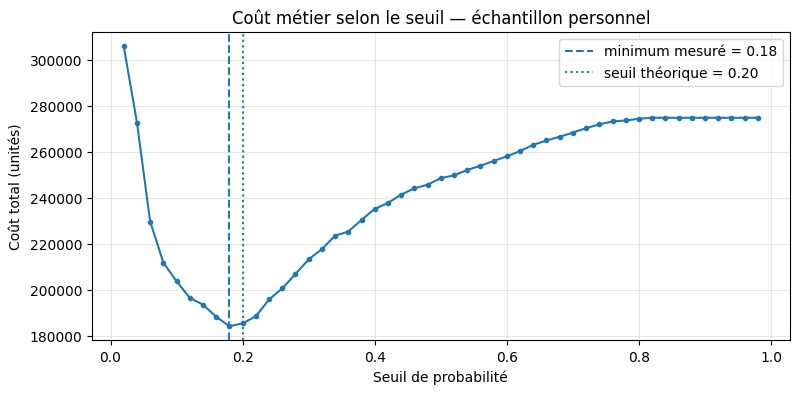

Seuil mesuré minimisant le coût : 0.18
Coût minimum mesuré : 184250
Coût au seuil par défaut 0,50 : 248625
Seuil théorique COUT_FP/(COUT_FP+COUT_FN) : 0.20
Écart de seuil : 0.02
Sur 14990 lignes, l'exactitude au seuil 0,50 vaut 82.55 %, tandis que le coût est 248625 unités. Le seuil minimisant le coût mesuré est 0.18 (coût 184250), contre 0.20 par la formule théorique. Cette formule suppose des probabilités calibrées et des coûts constants ; la calibration doit être vérifiée séparément.
  ok        un seuil écrit entre 0 et 1
  ok        deux coûts, des entiers positifs
  ok        l’écart est argumenté


In [28]:
# Q11 — Chercher le seuil qui minimise le coût métier sur l'échantillon personnel.
seuils_q11=np.round(np.arange(0.02,0.981,0.02),2)
couts_q11=[]
for s in seuils_q11:
    decisions=(proba_perso>=s).astype(int)
    couts_q11.append(cout(decisions,verite=yval_perso))
idx_min=int(np.argmin(couts_q11))
mon_seuil_choisi=float(seuils_q11[idx_min])
cout_a_mon_seuil=int(couts_q11[idx_min])
cout_du_seuil_par_defaut=int(cout((proba_perso>0.5).astype(int),verite=yval_perso))
# Courbe du coût
import matplotlib.pyplot as plt
plt.figure(figsize=(9,4))
plt.plot(seuils_q11,couts_q11,marker="o",markersize=3)
plt.axvline(mon_seuil_choisi,linestyle="--",label=f"minimum mesuré = {mon_seuil_choisi:.2f}")
plt.axvline(seuil_theorique,linestyle=":",label=f"seuil théorique = {seuil_theorique:.2f}")
plt.xlabel("Seuil de probabilité")
plt.ylabel("Coût total (unités)")
plt.title("Coût métier selon le seuil — échantillon personnel")
plt.grid(True,alpha=.3); plt.legend(); plt.show()
ecart_metrique_cout = (f"Sur {len(yval_perso)} lignes, l'exactitude au seuil 0,50 vaut "
    f"{accuracy_score(yval_perso,(proba_perso>0.5).astype(int))*100:.2f} %, tandis que le coût "
    f"est {cout_du_seuil_par_defaut} unités. Le seuil minimisant le coût mesuré est "
    f"{mon_seuil_choisi:.2f} (coût {cout_a_mon_seuil}), contre {seuil_theorique:.2f} par la formule "
    f"théorique. Cette formule suppose des probabilités calibrées et des coûts constants ; "
    "la calibration doit être vérifiée séparément.")
print(f"Seuil mesuré minimisant le coût : {mon_seuil_choisi:.2f}")
print(f"Coût minimum mesuré : {cout_a_mon_seuil}")
print(f"Coût au seuil par défaut 0,50 : {cout_du_seuil_par_defaut}")
print(f"Seuil théorique COUT_FP/(COUT_FP+COUT_FN) : {seuil_theorique:.2f}")
print(f"Écart de seuil : {abs(mon_seuil_choisi-seuil_theorique):.2f}")
print(ecart_metrique_cout)
controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil_choisi < 1, 'un seuil entre 0 et 1')
controle('deux coûts, des entiers positifs', lambda: cout_a_mon_seuil >= 0 and cout_du_seuil_par_defaut >= 0 and int(cout_a_mon_seuil)==cout_a_mon_seuil, 'le coût est un entier, en unités de coût')
controle('l’écart est argumenté', lambda: len(ecart_metrique_cout) > 40, 'chiffrez l’écart, et nommez les deux métriques comparées')

### Question 12 — Les deux classements  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le classement affiché se fait sur l'**exactitude** ; le cours vient de montrer que la décision
se paie en **coût**. Les deux classements ne désignent donc pas la même tête.

**Consigne.**
  1. prenez **deux stratégies** au moins sur votre échantillon (par exemple *n'alerte jamais*, et le
     modèle à deux seuils différents) ;
  2. classez-les deux fois, du meilleur au moins bon : par **exactitude**, puis par **coût** ;
  3. dites si la tête change, et ce que cela coûte de se fier à la métrique affichée.

**Livrables.** `classement_exactitude` · `classement_cout` · `tete_change`.

**Critère de réussite.** Deux stratégies suffisent : ce qui compte est que les deux classements
soient **mesurés sur la même population**.

*≈ 15 min.*


### Explication — Question 12 : comparer les classements

Quatre stratégies sont évaluées sur le même échantillon personnel. On les classe une fois par exactitude et une fois par coût métier. La comparaison des deux premières places montre si la métrique affichée conduit au même choix que le coût réel.

In [29]:
# Q12 — Classer les stratégies sur la même population selon exactitude puis coût.
strategies_q12={
    "N'alerte jamais":np.zeros(len(yval_perso),dtype=int),
    "Modèle seuil 0,50":(proba_perso>=0.50).astype(int),
    "Modèle seuil choisi":(proba_perso>=mon_seuil_choisi).astype(int),
    "Alerte toujours":np.ones(len(yval_perso),dtype=int)
}
resultats_q12=[]
for nom,dec in strategies_q12.items():
    resultats_q12.append({"stratégie":nom,
        "exactitude (%)":100*accuracy_score(yval_perso,dec),
        "coût":cout(dec,verite=yval_perso)})
tab_q12=pd.DataFrame(resultats_q12)
classement_exactitude=tab_q12.sort_values("exactitude (%)",ascending=False)["stratégie"].tolist()
classement_cout=tab_q12.sort_values("coût",ascending=True)["stratégie"].tolist()
tete_change=(f"Oui, la tête {'change' if classement_exactitude[0] != classement_cout[0] else 'ne change pas'} : "
    f"par exactitude, la meilleure stratégie est « {classement_exactitude[0]} » ; "
    f"par coût, c'est « {classement_cout[0]} ». Cela montre que la métrique affichée ne représente "
    "pas nécessairement la dépense métier.")
print("Résultats des stratégies sur le même échantillon")
display(tab_q12.sort_values("exactitude (%)",ascending=False).round(2))
print("Classement par exactitude :", " > ".join(classement_exactitude))
print("Classement par coût :", " > ".join(classement_cout))
print(tete_change)
controle('deux classements', lambda: len(classement_exactitude)>=2 and len(classement_cout)>=2, 'deux stratégies au moins, classées deux fois')
controle('la réponse est argumentée', lambda: len(str(tete_change)) > 40, 'dites si la tête change, et pourquoi')

Résultats des stratégies sur le même échantillon


,stratégie,exactitude (%),coût
1,"Modèle seuil 0,50",82.55,248625
0,N'alerte jamais,81.66,274900
2,Modèle seuil choisi,64.12,184250
3,Alerte toujours,18.34,306025


Classement par exactitude : Modèle seuil 0,50 > N'alerte jamais > Modèle seuil choisi > Alerte toujours
Classement par coût : Modèle seuil choisi > Modèle seuil 0,50 > N'alerte jamais > Alerte toujours
Oui, la tête change : par exactitude, la meilleure stratégie est « Modèle seuil 0,50 » ; par coût, c'est « Modèle seuil choisi ». Cela montre que la métrique affichée ne représente pas nécessairement la dépense métier.
  ok        deux classements
  ok        la réponse est argumentée


## Ce qu’on rend, et pourquoi ce format

**Trois tableaux**, comme au devoir 1 :

- **le tableau à quatre colonnes** — modèle · validation · affiché · écart — et vos trois phrases ;
- **le journal de nettoyage** — une ligne par décision : la décision, le choix fait, l’effet mesuré ;
- **le tableau d’essais** — une ligne par changement, avec l’attendu (un signe et une raison) et le
  mesuré.

Les **constats chiffrés** et les **hypothèses de features** appartiennent au **devoir 1**. Les
questions d’ici portent sur les baselines, le nettoyage et la mesure. Les tableaux qui les
portent sont ceux-ci. **Vos métriques, vos aires et votre seuil** (Q10, Q11) se lisent dans les cellules qui
les produisent.

La cellule qui suit affiche **les trois tableaux** remplis automatiquement, tels que vous les rendez.


### Explication de cette cellule de code

Cette cellule exécute l'étape décrite dans le commentaire Python. Exécute-la après les cellules précédentes : elle utilise les variables et les résultats déjà préparés. Observe les tableaux, les nombres et les messages affichés sous la cellule pour vérifier le résultat.

In [30]:
print("vos essais \n")
display(pd.DataFrame(ESSAIS))
print("votre journal de nettoyage \n")
display(pd.DataFrame(JOURNAL))
print("votre tableau à quatre colonnes \n")
try:
    tableau_quatre_colonnes = mon_tableau
except NameError:
    tableau_quatre_colonnes = pd.DataFrame()
display(tableau_quatre_colonnes)
print("vos contrôles \n")
display(pd.DataFrame(VERIFICATIONS))


vos essais 



""


votre journal de nettoyage 



,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,colonne candidate,écarter zone_clinique,une seule valeur sur toute la table,0.00,non
1,colonne candidate,écarter indice_meteo_jour,du bruit pur,-0.01,non
2,colonne candidate,écarter score_territorial,"42 052 valeurs, aucune raison de croire qu’ell...",-0.03,non
3,colonne candidate,écarter age_mois,age_mois ÷ 12 = age — sur 100 % des lignes (me...,0.00,non
4,colonne candidate,écarter cout_acte,"montant_acte = 13,68 × cout_acte, rapport cons...",0.00,non


votre tableau à quatre colonnes 



,modèle,validation,affiché,écart
0,Réponse constante,81.750559,NaN,0.000000
1,Règle personnelle âge >= 60,66.906835,NaN,-14.843724
2,HistGradientBoosting (cours),82.507755,81.81,0.757197
3,Régression logistique,82.207545,NaN,0.456987


vos contrôles 



,contrôle,tient
0,les données sont chargées,True
1,la table de travail est construite,True
2,"le découpage est fait, le modèle ajusté",True
3,les baselines sont mesurées,True
4,votre échantillon personnel est prêt,True
5,le pipeline tourne sur une table brute,True
6,le fichier est écrit,True
7,la règle est écrite,True
8,une exactitude en pourcentage,True
9,un écart exprimé en erreurs-types,False


## Rendre le travail

1. **Exécutez tout** le carnet (`Run All`), pour que les tableaux soient remplis.
2. **Déposez** ce carnet dans votre dépôt GitHub personnel. Mettez **avec** lui votre déclaration d’usage de
   l’IA, dans le **même commit** :
   - téléchargez le modèle **`DECLARATION_modele.md`** depuis le **dépôt du cours** ;
   - recopiez-le dans votre dépôt sous le nom **`declaration_DM2.md`** ;
   - remplissez-le : les deux scores, ce que vous avez produit seul, ce que vous avez fait
     avec un assistant, et ce que vous ne sauriez pas expliquer.
3. Vérifiez que le lien de votre dépôt est bien à jour dans le formulaire de la classe.

> Un travail non déposé n’existe pas.
